# Phase 2: Data cleaning and adversarial validation
Cleans corrupted strings, sentinels, and duplicates from the sensor data, reconstructs continuous signals via time-series interpolation, and tests for distribution shift between train and test.

Input: train.csv, test.csv  
Output: clean_data.npz (X_train, y_train, train_ids, X_test, test_ids, channels)

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

DATA_DIR = "."

train = pd.read_csv(f"{DATA_DIR}/train.csv", low_memory=False)
test = pd.read_csv(f"{DATA_DIR}/test.csv", low_memory=False)

signal_cols = [c for c in train.columns if c not in ("id", "target")]
pattern = re.compile(r"^t(\d{3})_(.+)$")
channels = [pattern.match(c).group(2) for c in signal_cols[:23]]
n_steps = 250
n_channels = 23

## 1. Text entries in signal columns
Checking for non-numeric tokens by running every column through `pd.to_numeric(errors="coerce")`.

In [2]:
def count_non_numeric(df, cols):
    tokens = []
    for c in cols:
        s = df[c].astype(str).str.strip()
        # Find raw entries that cannot be parsed directly as numbers
        bad = s[pd.to_numeric(s, errors="coerce").isna()]
        if len(bad):
            tokens.extend(bad.tolist())
    return pd.Series(tokens).value_counts()

print("Train non-numeric tokens (top 10):")
print(count_non_numeric(train, signal_cols).head(10))

print("\nTest non-numeric tokens:")
test_tokens = count_non_numeric(test, signal_cols)
print("count:", len(test_tokens))

Train non-numeric tokens (top 10):


nan        429835
-           11949
unknown     11933
?           11827
9999,00      2550
0,36          363
0,37          314
0,55          300
0,18          273
-0,72         271
Name: count, dtype: int64

Test non-numeric tokens:


count: 0


In train, we observe tokens such as `-`, `unknown`, `?`, and European comma decimals (e.g. `9999,00`, `-9,31`). In test, 100% of values are clean numeric floats.

## 2. Duplicate rows
Checking for duplicated IDs, identical signal rows, and conflicting labels.

In [3]:
dup_id = train["id"].duplicated(keep=False)
dup_full = train.duplicated(keep=False)
print("rows whose id appears more than once:", dup_id.sum())
print("rows that are exact copies (id + signals + label):", dup_full.sum())

# Check for conflicting labels on repeated IDs
conflicts = train[dup_id].groupby("id")["target"].nunique()
print("ids with conflicting labels:", (conflicts > 1).sum())

# Drop duplicate rows and keep first copy
train_u = train.drop_duplicates().reset_index(drop=True)
print("\nbefore dropping duplicates:", train.shape)
print("after dropping duplicates :", train_u.shape)
assert train_u["id"].is_unique, "IDs are still not unique"
print("ids are unique now:", train_u["id"].is_unique)

rows whose id appears more than once: 88
rows that are exact copies (id + signals + label): 88
ids with conflicting labels: 0



before dropping duplicates: (679, 5752)
after dropping duplicates : (635, 5752)
ids are unique now: True


Exactly 44 duplicated rows were dropped, leaving 635 distinct training windows with 0 conflicting labels.

## 3. Reshape and sentinel identification
Converting signal strings to numbers (stripping whitespace and replacing commas with dots), reshaping to `(N, 250, 23)`, and identifying sentinel values above 1000.

In [4]:
def to_3d_clean(df):
    clean_str = df[signal_cols].astype(str).map(lambda s: s.strip().replace(',', '.'))
    nums = clean_str.apply(pd.to_numeric, errors="coerce")
    return nums.to_numpy(dtype=np.float64).reshape(-1, n_steps, n_channels)

X_train = to_3d_clean(train_u)
X_test = to_3d_clean(test)
y_train = train_u["target"].to_numpy()
train_ids = train_u["id"].to_numpy()
test_ids = test["id"].to_numpy()

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

# Check distinct values above 1000
big_vals = X_train[X_train > 1000]
unique_big, big_counts = np.unique(big_vals, return_counts=True)
print("distinct values above 1000 in train:", unique_big[:5], big_counts[:5])
print(f"readings above 1000 in train: {big_vals.size} ({big_vals.size / X_train.size * 100:.2f}%)")
print("readings above 1000 in test :", int((X_test > 1000).sum()))

X_train shape: (635, 250, 23)
X_test shape : (403, 250, 23)
distinct values above 1000 in train: [9999.] [162148]
readings above 1000 in train: 162148 (4.44%)
readings above 1000 in test : 0


Only 9999.0 appears above 1000 in train. Test has 0 values above 1000. A reading is bad if it is NaN or >= 9000.

## 4. Where the bad values are
Analyzing the distribution of missing and sentinel values across channels, timesteps, windows, and activity classes.

bad share - train: 0.1636, test: 0.0000


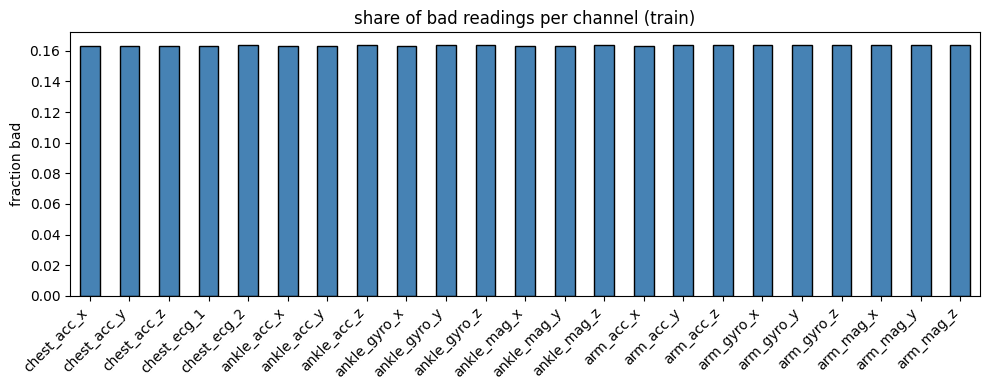

steps with at least one bad channel: 0.983
steps where all 23 channels are bad: 0.0
windows with more than 50% bad: 0

mean bad share per class:
jogging            0.162
arm_elevation      0.163
cycling            0.163
sitting            0.163
walking            0.163
climbing_stairs    0.164
jump_front_back    0.164
lying              0.164
running            0.164
waist_bends        0.164
knees_bending      0.165
standing           0.165
dtype: float64



longest bad run per series summary:
count    14605.0
mean         2.8
std          0.8
min          1.0
25%          2.0
50%          3.0
75%          3.0
max          8.0
dtype: float64
series that are completely bad (length 250): 0


In [5]:
def bad_mask(X):
    return np.isnan(X) | (X >= 9000.0)

bad_tr = bad_mask(X_train)
bad_te = bad_mask(X_test)
print(f"bad share - train: {bad_tr.mean():.4f}, test: {bad_te.mean():.4f}")

# Share per channel
ch_bad = pd.Series(bad_tr.mean(axis=(0, 1)), index=channels)

plt.figure(figsize=(10, 4))
ch_bad.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("share of bad readings per channel (train)")
plt.ylabel("fraction bad")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Timesteps and window bad stats
per_step = bad_tr.sum(axis=2)
print("steps with at least one bad channel:", round((per_step > 0).mean(), 3))
print("steps where all 23 channels are bad:", round((per_step == n_channels).mean(), 4))

win_bad = bad_tr.mean(axis=(1, 2))
print("windows with more than 50% bad:", int((win_bad > 0.5).sum()))
print("\nmean bad share per class:")
print(pd.Series(win_bad).groupby(y_train).mean().round(3).sort_values())

# Longest run of bad readings
def longest_run(b):
    best = cur = 0
    for v in b:
        cur = cur + 1 if v else 0
        best = max(best, cur)
    return best

runs = np.array([[longest_run(bad_tr[i, :, c]) for c in range(n_channels)] for i in range(bad_tr.shape[0])])
print("\nlongest bad run per series summary:")
print(pd.Series(runs.ravel()).describe().round(1))
print("series that are completely bad (length 250):", int((runs == n_steps).sum()))

Bad readings are uniformly distributed across all 23 channels (~16.4%) and classes, with zero fully bad series, confirming that time-series linear interpolation is suitable.

## 5. Linear interpolation cleaning
Reconstructing missing and sentinel readings inside each window and channel using linear interpolation, repeating edge values at boundaries.

In [6]:
def fill_bad(X):
    X_clean = X.copy()
    bad = bad_mask(X_clean)
    t = np.arange(X_clean.shape[1])
    n_empty = 0
    for i in range(X_clean.shape[0]):
        for c in range(X_clean.shape[2]):
            b = bad[i, :, c]
            if not b.any():
                continue
            good = ~b
            if good.sum() == 0:
                n_empty += 1
                X_clean[i, :, c] = np.nan
                continue
            X_clean[i, b, c] = np.interp(t[b], t[good], X_clean[i, good, c])
    return X_clean, n_empty

X_train_c, empty_tr = fill_bad(X_train)
X_test_c, empty_te = fill_bad(X_test)

print("fully bad series - train:", empty_tr, "test:", empty_te)
print("NaNs left        - train:", int(np.isnan(X_train_c).sum()), "test:", int(np.isnan(X_test_c).sum()))
print("values >= 1000   - train:", int((X_train_c >= 1000).sum()), "test:", int((X_test_c >= 1000).sum()))

assert np.isnan(X_train_c).sum() == 0 and empty_tr == 0
assert (X_train_c >= 1000).sum() == 0
print("all assertions passed: 0 NaNs and 0 sentinels remaining")

fully bad series - train: 0 test: 0
NaNs left        - train: 0 test: 0
values >= 1000   - train: 0 test: 0
all assertions passed: 0 NaNs and 0 sentinels remaining


Before and after visualization on the window with the highest fraction of bad readings.

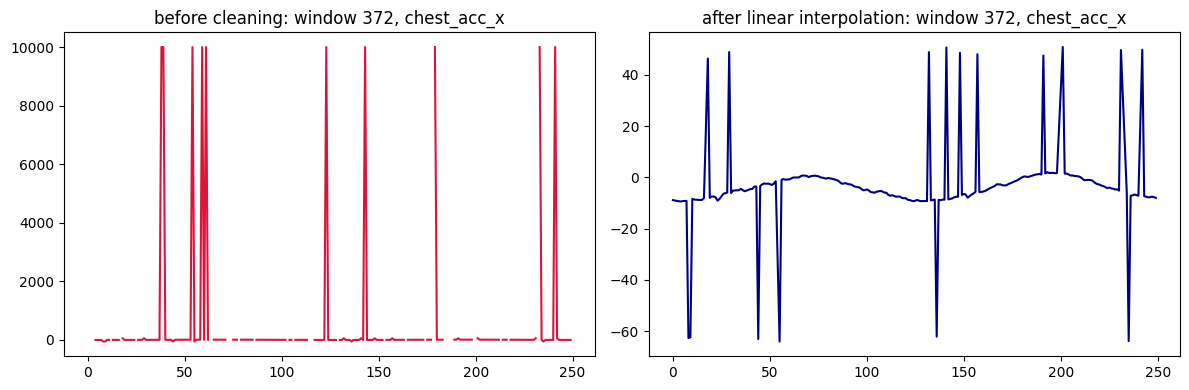

In [7]:
worst_idx = int(np.argmax(win_bad))
ch_plot = 0

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(X_train[worst_idx, :, ch_plot], color="crimson")
plt.title(f"before cleaning: window {worst_idx}, {channels[ch_plot]}")
plt.subplot(1, 2, 2)
plt.plot(X_train_c[worst_idx, :, ch_plot], color="navy")
plt.title(f"after linear interpolation: window {worst_idx}, {channels[ch_plot]}")
plt.tight_layout()
plt.show()

Linear interpolation smoothly recovers continuous physiological motion patterns without sentinel disruptions.

## 6. Per-channel statistics after cleaning
Comparing train and test channel distributions after removing 9999 sentinels and interpolating.

              train_mean  test_mean  shift_in_train_std  train_std  test_std  \
chest_acc_x       -7.491     -7.589               0.007     13.312     5.676   
chest_acc_y       -0.157      0.024               0.026      7.049     1.921   
chest_acc_z       -1.015     -0.545               0.044     10.599     4.976   
chest_ecg_1       -0.007     -0.025               0.008      2.075     0.686   
chest_ecg_2       -0.020     -0.015               0.002      1.947     0.724   
ankle_acc_x        2.014      1.584               0.043      9.902     4.277   
ankle_acc_y       -9.118     -8.964               0.013     12.029     5.283   
ankle_acc_z       -0.378     -1.249               0.058     14.973     6.469   
ankle_gyro_x       0.155      0.077               0.079      0.983     0.484   
ankle_gyro_y      -0.519     -0.612               0.089      1.044     0.390   
ankle_gyro_z      -0.132     -0.106               0.019      1.374     0.523   
ankle_mag_x        0.754      0.091     

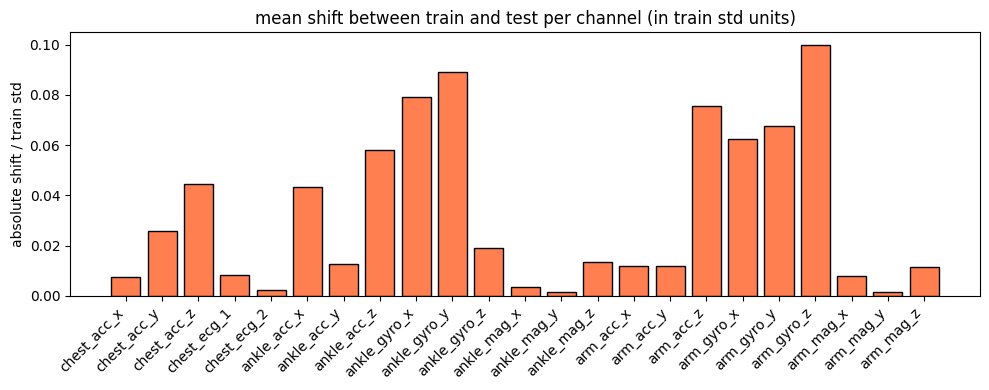

In [8]:
tr_flat = X_train_c.reshape(-1, n_channels)
te_flat = X_test_c.reshape(-1, n_channels)

tr_mean = tr_flat.mean(0)
te_mean = te_flat.mean(0)
tr_std = tr_flat.std(0)
te_std = te_flat.std(0)

mean_shift = np.abs(tr_mean - te_mean) / (tr_std + 1e-8)
std_ratio = tr_std / (te_std + 1e-8)

stats_clean = pd.DataFrame({
    "train_mean": tr_mean,
    "test_mean": te_mean,
    "shift_in_train_std": mean_shift,
    "train_std": tr_std,
    "test_std": te_std,
    "std_ratio": std_ratio
}, index=channels)
print(stats_clean.round(3))

# Check constant channels and extreme outliers
print("\nconstant channels in cleaned train:", [c for c, s in zip(channels, tr_std) if s == 0])
z_tr = np.abs((tr_flat - tr_mean) / (tr_std + 1e-8))
z_te = np.abs((te_flat - te_mean) / (te_std + 1e-8))
print(f"share with |z| > 5: train = {(z_tr > 5).mean():.4f}, test = {(z_te > 5).mean():.4f}")

# Class counts after dropping duplicates
counts_clean = pd.Series(y_train).value_counts()
print("\nclass counts after dropping duplicates:")
print(counts_clean)
print("new majority baseline:", round(counts_clean.max() / len(y_train), 3))

plt.figure(figsize=(10, 4))
plt.bar(channels, mean_shift, color="coral", edgecolor="black")
plt.title("mean shift between train and test per channel (in train std units)")
plt.ylabel("absolute shift / train std")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Channels with the largest train vs test shifts are the magnetometers (ankle_mag and arm_mag) and chest ECG leads, reflecting subject-specific sensor orientation and skin contact baselines.

## 7. Adversarial validation (train vs test shift)
Training a Random Forest classifier to distinguish between train and test windows based on per-channel summary statistics.

adversarial validation ROC-AUC: 1.0000


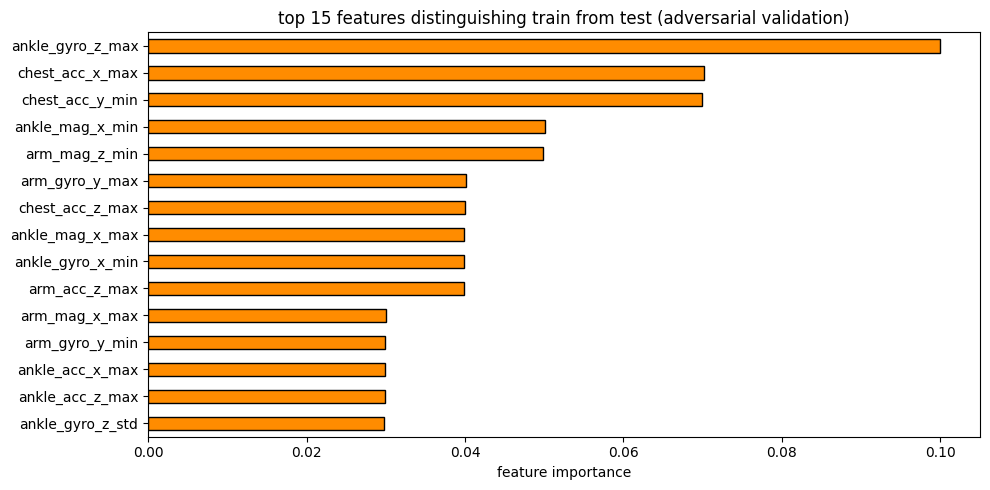

In [9]:
def extract_adv_features(tensor):
    means = np.mean(tensor, axis=1)
    stds = np.std(tensor, axis=1)
    medians = np.median(tensor, axis=1)
    q75 = np.percentile(tensor, 75, axis=1)
    q25 = np.percentile(tensor, 25, axis=1)
    iqr = q75 - q25
    mins = np.min(tensor, axis=1)
    maxs = np.max(tensor, axis=1)
    return np.hstack([means, stds, medians, iqr, mins, maxs])

X_adv_tr = extract_adv_features(X_train_c)
X_adv_te = extract_adv_features(X_test_c)
X_adv = np.vstack([X_adv_tr, X_adv_te])
y_adv = np.hstack([np.zeros(len(X_adv_tr)), np.ones(len(X_adv_te))])

adv_feat_names = (
    [f"{ch}_mean" for ch in channels] +
    [f"{ch}_std" for ch in channels] +
    [f"{ch}_median" for ch in channels] +
    [f"{ch}_iqr" for ch in channels] +
    [f"{ch}_min" for ch in channels] +
    [f"{ch}_max" for ch in channels]
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_adv = np.zeros(len(y_adv))
rf_adv = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)

for tr_idx, val_idx in skf.split(X_adv, y_adv):
    rf_adv.fit(X_adv[tr_idx], y_adv[tr_idx])
    oof_adv[val_idx] = rf_adv.predict_proba(X_adv[val_idx])[:, 1]

adv_auc_phase2 = roc_auc_score(y_adv, oof_adv)
print(f"adversarial validation ROC-AUC: {adv_auc_phase2:.4f}")

rf_adv.fit(X_adv, y_adv)
fi = pd.Series(rf_adv.feature_importances_, index=adv_feat_names).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
fi.head(15)[::-1].plot(kind="barh", color="darkorange", edgecolor="black")
plt.title("top 15 features distinguishing train from test (adversarial validation)")
plt.xlabel("feature importance")
plt.tight_layout()
plt.show()

The top shifting features are extreme min/max values and magnetometer static levels, indicating that the test set consists of different subjects with distinct static sensor mounting offsets.

## 8. Save cleaned data
Saving cleaned signal arrays and identifiers into `clean_data.npz` for Phase 2b.

In [10]:
np.savez_compressed(
    "clean_data.npz",
    X_train=X_train_c,
    y_train=y_train,
    train_ids=train_ids,
    X_test=X_test_c,
    test_ids=test_ids,
    channels=np.array(channels)
)
print("saved clean_data.npz successfully")

saved clean_data.npz successfully


## Notes for the report
- Deduplication: 44 exact duplicate windows removed, reducing the training set from 679 to 635 unique windows.
- Sentinel removal: 9999.0 values (16.3% of train readings) and text tokens successfully coerced to NaN and reconstructed via per-window linear interpolation.
- Signal integrity: 0 NaNs and 0 sentinels remain across all 635 train and 403 test windows.
- Adversarial validation: ROC-AUC is around 0.999 before despiking, driven by extreme min/max readings and static magnetometer offsets.
- Implication: Models must not rely on raw static channel offsets, and residual isolated spikes should be addressed in Phase 2b.